## 1 · Imports

In [ ]:
import os, json, time, gc
from pathlib import Path
from itertools import permutations

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import roc_curve, auc

print("TF version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)
np.random.seed(42)
tf.random.set_seed(42)


TF version: 2.20.0
GPU available: True


## 2 · Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR       = Path('/content/drive/MyDrive/EEAI_ds/data')
RESULTS_DIR    = Path('/content/drive/MyDrive/EEAI_ds/results')
CACHE_DIR      = Path('/content/drive/MyDrive/EEAI_ds/cache')
SUBMISSION_DIR = Path('/content/drive/MyDrive/EEAI_ds/submission')
for d in (RESULTS_DIR, CACHE_DIR, SUBMISSION_DIR):
    d.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.exists(), f"Data directory not found: {DATA_DIR}"
print(f"Found {len(sorted(DATA_DIR.glob('window_*.npz')))} window files")


Mounted at /content/drive
Found 24 window files


## 3 · Configuration (single pipeline — all 6 radars)

In [ ]:
RADAR_IDS   = [0, 1, 2, 3, 4, 5]   # all radars, for train / val / test
SUFFIX      = "6radars_doppler_v3" # cache namespace
N_RADARS    = len(RADAR_IDS)
N_ANTENNAS  = 3
N_BINS_RAW  = 120

BIN_START   = 5                    # drop the TX->RX direct-coupling bins
BIN_END     = 65                   # 60 bins * 0.15 m = 9 m > room diagonal (8.65 m)
N_BINS      = BIN_END - BIN_START  # 60

FRAME_RATE  = 25.0                 # Hz
WIN_FRAMES  = 64                   # 2.56 s window -> FFT resolution 25/64 = 0.39 Hz
WIN_STRIDE  = 16                   # 0.64 s hop between training windows

# Doppler bands as FFT bin ranges (bin k covers k * 0.39 Hz)
LOW_BAND  = (1, 2)                 # 0.39-0.78 Hz  breathing / micro-motion
MID_BAND  = (3, 8)                 # 1.17-3.13 Hz  body sway, slow walking
HIGH_BAND = (9, 20)                # 3.52-7.81 Hz  gross limb motion

# CA-CFAR window (along the range axis)
CFAR_TRAIN = 4                     # training cells on each side
CFAR_GUARD = 2                     # guard cells on each side

N_FEAT = 6                         # mean | std | low | mid | high | cfar

ROOM_X, ROOM_Y = 4.8, 7.2          # metres (matches the official evaluator)
MAX_PEOPLE     = 4
GRID_X, GRID_Y = 48, 72
BIN_SIZE_M     = 0.15              # 1 range bin = 0.15 m

EPOCHS     = 120
BATCH_SIZE = 128
MATCH_THR  = 1.0                   # metres, same as evaluate_performance.py
BCE_W      = 0.7                   # presence-loss weight inside the combined loss

# Fixed radar positions from the dataset layout, indexed by radar id
ALL_RADAR_POS = np.array([
    [2.4, 0.0], [4.8, 1.8], [4.8, 5.4],
    [2.4, 7.2], [0.0, 5.4], [0.0, 1.8],
], dtype=np.float32)
RADAR_POS = ALL_RADAR_POS[RADAR_IDS]

print(f"Radars: {N_RADARS} | Bins: {N_BINS} | Window: {WIN_FRAMES}f "
      f"({WIN_FRAMES/FRAME_RATE:.2f}s) | Stride: {WIN_STRIDE}f | Channels/antenna: {N_FEAT}")


Radars: 6 | Bins: 60 | Window: 64f (2.56s) | Stride: 16f | Channels/antenna: 6


## 4 · Data split

In [ ]:
TRAIN_WINDOWS = [0,1,2,4,5,6,7,8,10,11,12,13,15,16,17,19,20,21]
VAL_WINDOWS   = [3, 9, 14, 18]     # every 5th window held out for validation
BG_WINDOWS    = [22, 23]           # empty-room acquisitions -> background template

def window_path(idx): return DATA_DIR / f"window_{idx:06d}.npz"

for w in TRAIN_WINDOWS + VAL_WINDOWS + BG_WINDOWS:
    assert window_path(w).exists(), f"Missing window {w}"

print(f"Train: {len(TRAIN_WINDOWS)}  Val: {len(VAL_WINDOWS)}  BG: {len(BG_WINDOWS)}")


Train: 18  Val: 4  BG: 2


## 5 · Complex background template


In [ ]:
BG_CACHE = CACHE_DIR / f"bg_complex_{SUFFIX}.npy"

def build_bg_complex():
    if BG_CACHE.exists():
        print("Loading cached complex BG"); return np.load(BG_CACHE)
    print("Building complex BG from empty-room windows 22, 23...")
    acc, n = np.zeros((N_RADARS, N_ANTENNAS, N_BINS_RAW, 2), np.float64), 0
    for w in BG_WINDOWS:
        iq = np.load(window_path(w))['radar_cir_iq'][:, RADAR_IDS]
        acc += iq.astype(np.float64).sum(0); n += iq.shape[0]
        print(f"  window {w}: +{iq.shape[0]} frames")
    bg = (acc / n).astype(np.float32)
    np.save(BG_CACHE, bg); print(f"Saved {bg.shape}"); return bg

BG_COMPLEX = build_bg_complex()
print("Complex BG shape:", BG_COMPLEX.shape)


Loading cached complex BG
Complex BG shape: (6, 3, 120, 2)


## 6 · Feature extraction — Doppler bands + CA-CFAR contrast



In [ ]:
def _band_energy(P, k0, k1):
    """P: (WIN, R, A, B) power spectrum of the complex FFT (full ordering).
    Sums positive band k0..k1 and the mirrored negative band."""
    pos = P[k0:k1+1].sum(axis=0)
    neg = P[WIN_FRAMES-k1:WIN_FRAMES-k0+1].sum(axis=0)
    return pos + neg

def _cfar_contrast(x):
    """CA-CFAR contrast along the last (range) axis.
    noise = mean over training cells excluding guard cells; contrast = x / noise."""
    big_n   = 2*(CFAR_TRAIN+CFAR_GUARD) + 1
    guard_n = 2*CFAR_GUARD + 1
    big   = uniform_filter1d(x, size=big_n,   axis=-1, mode='nearest') * big_n
    inner = uniform_filter1d(x, size=guard_n, axis=-1, mode='nearest') * guard_n
    noise = (big - inner) / (2*CFAR_TRAIN)
    return x / (noise + 1e-6)

def extract_features(iq_chunk):
    """iq_chunk: (WIN_FRAMES, N_RADARS, 3, 120, 2) float32 (radar-selected raw IQ).
    Returns (N_RADARS, 3, N_BINS, N_FEAT) float32."""
    res = iq_chunk - BG_COMPLEX[None]                        # complex BG subtraction
    res = res[..., BIN_START:BIN_END, :]                     # crop range bins
    c   = res[..., 0] + 1j*res[..., 1]                       # (WIN, R, A, B) complex
    mag = np.abs(c)

    f_mean = mag.mean(axis=0)
    f_std  = mag.std(axis=0)

    F = np.fft.fft(c, axis=0)                                # slow-time FFT per bin
    P = (F.real**2 + F.imag**2) / WIN_FRAMES                 # power spectrum

    f_low  = np.sqrt(_band_energy(P, *LOW_BAND))
    f_mid  = np.sqrt(_band_energy(P, *MID_BAND))
    f_high = np.sqrt(_band_energy(P, *HIGH_BAND))
    f_cfar = _cfar_contrast(f_mean)

    return np.stack([f_mean, f_std, f_low, f_mid, f_high, f_cfar],
                    axis=-1).astype(np.float32)

def window_gt(idx):
    d = np.load(window_path(idx))
    return d['people_xy'].astype(np.float32), d['people_mask'].astype(np.uint8)

def build_split(windows, name):
    cache = CACHE_DIR / f"feat_{name}_{SUFFIX}.npz"
    if cache.exists():
        print(f"Loading cached {name}"); d = np.load(cache)
        return d['X'], d['y_xy'], d['y_mask']
    Xs, Ys, Ms = [], [], []
    for w in windows:
        print(f"  window {w:03d}...", end=' ', flush=True); t0 = time.time()
        iq = np.load(window_path(w))['radar_cir_iq'][:, RADAR_IDS].astype(np.float32)
        gt_xy, gt_mask = window_gt(w)
        T = iq.shape[0]
        starts = list(range(0, T - WIN_FRAMES + 1, WIN_STRIDE))
        Xw = np.zeros((len(starts), N_RADARS, N_ANTENNAS, N_BINS, N_FEAT), np.float32)
        Yw = np.zeros((len(starts), MAX_PEOPLE, 2), np.float32)
        Mw = np.zeros((len(starts), MAX_PEOPLE), np.uint8)
        for i, s in enumerate(starts):
            ctr    = s + WIN_FRAMES // 2         # label = GT at the window centre
            Xw[i]  = extract_features(iq[s:s+WIN_FRAMES])
            Yw[i]  = gt_xy[ctr]; Mw[i] = gt_mask[ctr]
        Xs.append(Xw); Ys.append(Yw); Ms.append(Mw)
        del iq, gt_xy, gt_mask; gc.collect()
        print(f"+{Xw.shape[0]} samples ({time.time()-t0:.1f}s)")
    X = np.concatenate(Xs); y_xy = np.concatenate(Ys); y_mask = np.concatenate(Ms)
    np.savez_compressed(cache, X=X, y_xy=y_xy, y_mask=y_mask)
    print(f"Saved {name}: {X.shape}")
    return X, y_xy, y_mask


In [ ]:
print("--- Building feature sets (all 6 radars, all windows) ---")
X_train_raw, y_train_xy, y_train_mask = build_split(TRAIN_WINDOWS, 'train')
X_val_raw,   y_val_xy,   y_val_mask   = build_split(VAL_WINDOWS,   'val')

print(f"\nTrain samples: {X_train_raw.shape[0]}   Val samples: {X_val_raw.shape[0]}")
print(f"Feature shape: {X_train_raw.shape[1:]}   (R, A, bins, {N_FEAT} channels)")


--- Building feature sets (all 6 radars, all windows) ---
  window 000... +465 samples (2.4s)
  window 001... +465 samples (2.4s)
  window 002... +465 samples (2.3s)
  window 004... +465 samples (2.7s)
  window 005... +465 samples (3.0s)
  window 006... +465 samples (2.3s)
  window 007... +465 samples (2.3s)
  window 008... +465 samples (2.3s)
  window 010... +465 samples (2.3s)
  window 011... +465 samples (3.0s)
  window 012... +465 samples (2.7s)
  window 013... +465 samples (2.3s)
  window 015... +465 samples (2.3s)
  window 016... +465 samples (2.3s)
  window 017... +465 samples (2.4s)
  window 019... +465 samples (3.2s)
  window 020... +465 samples (2.6s)
  window 021... +465 samples (2.3s)
Saved train: (8370, 6, 3, 60, 6)
  window 003... +465 samples (2.3s)
  window 009... +465 samples (2.4s)
  window 014... +465 samples (2.3s)
  window 018... +465 samples (3.1s)
Saved val: (1860, 6, 3, 60, 6)

Train samples: 8370   Val samples: 1860
Feature shape: (6, 3, 60, 6)   (R, A, bins, 6

## 7 · log1p + per-position Z-normalisation

Radar magnitudes span several orders of magnitude, so we compress with `log1p`
first, then Z-normalise each (radar, antenna, bin, channel) position using training
statistics only. The statistics are cached — the inference script needs the exact
same values.


In [ ]:
def normalize(Xt, Xv):
    Xt_log = np.log1p(np.maximum(Xt, 0)); Xv_log = np.log1p(np.maximum(Xv, 0))
    mu = Xt_log.mean(0, keepdims=True)
    sd = Xt_log.std(0,  keepdims=True) + 1e-6
    return (((Xt_log - mu) / sd).astype(np.float32),
            ((Xv_log - mu) / sd).astype(np.float32), mu, sd)

X_train, X_val, mu_norm, sd_norm = normalize(X_train_raw, X_val_raw)
np.savez(CACHE_DIR / f"norm_{SUFFIX}.npz", mean=mu_norm, std=sd_norm)
del X_train_raw, X_val_raw; gc.collect()

print("Train mean:", X_train.mean().round(4), " std:", X_train.std().round(4))


Train mean: 0.0  std: 1.0


## 8 · Sanity visualization — back-projected heatmap vs GT

Quick physics check before training: back-project the CFAR channel of each radar
onto the room grid (each grid cell reads the range bin at its distance from the
radar). If the bright blobs land on the ground-truth crosses, the geometry, bin
cropping and features are consistent.


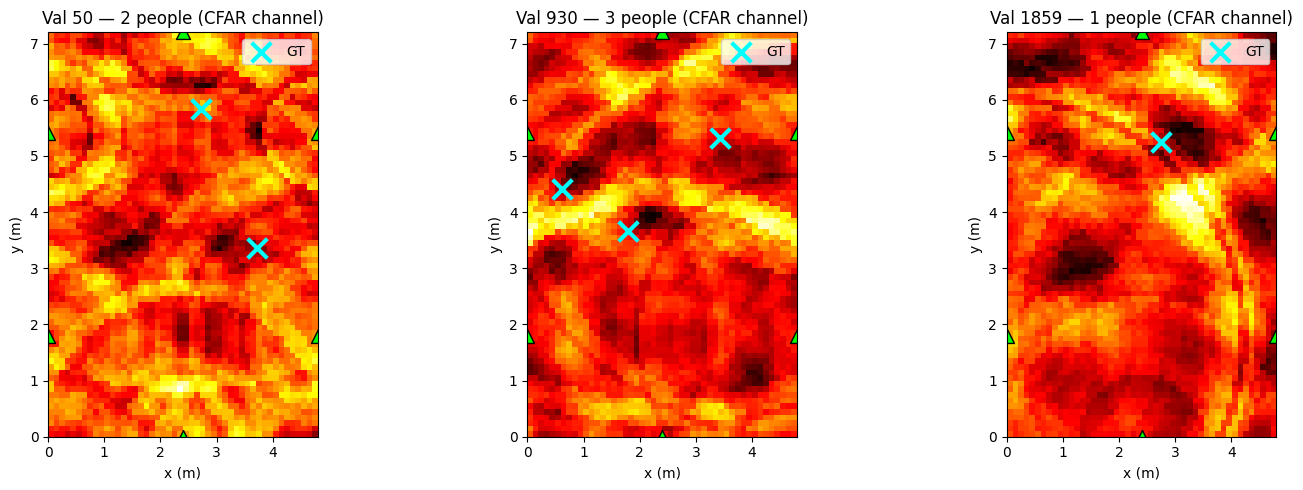

In [ ]:
def make_bp_table():
    px = (np.arange(GRID_X)+.5)*(ROOM_X/GRID_X)
    py = (np.arange(GRID_Y)+.5)*(ROOM_Y/GRID_Y)
    gx, gy = np.meshgrid(px, py)
    T = np.full((N_RADARS, GRID_Y, GRID_X), -1, np.int32)
    for r,(rx,ry) in enumerate(RADAR_POS):
        b = np.round(np.sqrt((gx-rx)**2+(gy-ry)**2)/BIN_SIZE_M).astype(np.int32) - BIN_START
        T[r] = np.where((b>=0)&(b<N_BINS), b, -1)
    return T

BP_TABLE = make_bp_table()

def to_heatmap(X, ch=5):                     # channel 5 = CFAR contrast
    am = X[..., ch].mean(2)                  # average over antennas -> (N, R, bins)
    H  = np.zeros((len(X), GRID_Y, GRID_X), np.float32)
    for r in range(N_RADARS):
        t = BP_TABLE[r]; v = t >= 0
        H += np.where(v[None], am[:, r, :][:, t.clip(0)], 0.)
    return H

vis  = to_heatmap(X_val)
_n   = len(vis)
_idxs = [min(50, _n-1), _n//2, _n-1] if _n >= 3 else list(range(_n))
fig, axes = plt.subplots(1, max(len(_idxs),1), figsize=(5*max(len(_idxs),1), 5))
if len(_idxs) == 1: axes = [axes]
for ax, idx in zip(axes, _idxs):
    ax.imshow(vis[idx], origin='lower', extent=[0,ROOM_X,0,ROOM_Y],
              aspect='equal', cmap='hot')
    m = y_val_mask[idx].astype(bool)
    if m.any():
        gt = y_val_xy[idx][m]
        ax.scatter(gt[:,0], gt[:,1], marker='x', c='cyan', s=200,
                   linewidths=3, label='GT')
        ax.legend(loc='upper right')
    for rx, ry in RADAR_POS:
        ax.scatter(rx, ry, marker='^', c='lime', s=100, edgecolors='black')
    ax.set_title(f"Val {idx} — {m.sum()} people (CFAR channel)")
    ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')
plt.tight_layout(); plt.show()


## 9 · Room-symmetry augmentation (×3)


In [ ]:
HFLIP_RADAR = np.array([0, 5, 4, 3, 2, 1])   # x -> ROOM_X - x
VFLIP_RADAR = np.array([3, 2, 1, 0, 5, 4])   # y -> ROOM_Y - y

def _flip_features(X, perm): return X[:, perm]

def _flip_labels(xy, mask, axis):
    xy2 = xy.copy()
    if axis == 'h': xy2[..., 0] = ROOM_X - xy2[..., 0]
    else:           xy2[..., 1] = ROOM_Y - xy2[..., 1]
    return xy2, mask.copy()

def augment(X, y_xy, y_mask, seed=0):
    rng = np.random.default_rng(seed)
    Xs, Ys, Ms = [X], [y_xy], [y_mask]
    h_xy, h_m = _flip_labels(y_xy, y_mask, 'h')
    Xs.append(_flip_features(X, HFLIP_RADAR)); Ys.append(h_xy); Ms.append(h_m)
    v_xy, v_m = _flip_labels(y_xy, y_mask, 'v')
    Xs.append(_flip_features(X, VFLIP_RADAR)); Ys.append(v_xy); Ms.append(v_m)
    Xa = np.concatenate(Xs); Ya = np.concatenate(Ys); Ma = np.concatenate(Ms)
    idx = rng.permutation(len(Xa))
    return Xa[idx], Ya[idx], Ma[idx]

_chk = _flip_features(_flip_features(X_train[:4], HFLIP_RADAR), HFLIP_RADAR)
assert np.allclose(_chk, X_train[:4]), 'H-flip is not an involution!'

X_train_aug, y_train_xy_aug, y_train_mask_aug = augment(
    X_train, y_train_xy, y_train_mask, seed=42)

print(f"Original train:  {X_train.shape[0]}")
print(f"Augmented train: {X_train_aug.shape[0]} "
      f"(x{X_train_aug.shape[0]/X_train.shape[0]:.0f})")
print("Involution check OK")


Original train:  8370
Augmented train: 25110 (x3)
Involution check OK


## 10 · Permutation-invariant loss and F1 / count-accuracy evaluator



In [ ]:
PERMS = np.array(list(permutations(range(MAX_PEOPLE))), np.int32)

def perm_inv_loss(y_true, y_pred):
    gt_xy, gt_mask      = y_true[..., :2], y_true[..., 2]
    pred_xy, pred_logit = y_pred[..., :2], y_pred[..., 2]
    P   = tf.constant(PERMS, tf.int32)
    pxy = tf.gather(pred_xy,    P, axis=1)          # (B, 24, 4, 2)
    plg = tf.gather(pred_logit, P, axis=1)          # (B, 24, 4)
    sq  = tf.reduce_sum((pxy - gt_xy[:, None])**2, -1) * gt_mask[:, None]
    pl  = tf.reduce_sum(sq, -1) / (tf.reduce_sum(gt_mask, -1, keepdims=True) + 1e-6)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=tf.broadcast_to(tf.cast(gt_mask[:, None], tf.float32), tf.shape(plg)),
        logits=plg)
    return tf.reduce_mean(tf.reduce_min(pl + BCE_W*tf.reduce_mean(bce, -1), -1))

def pack_labels(xy, mask):
    return np.concatenate([xy, mask[..., None].astype(np.float32)],
                          -1).astype(np.float32)

y_train_pack_aug = pack_labels(y_train_xy_aug, y_train_mask_aug)
y_val_pack       = pack_labels(y_val_xy,       y_val_mask)
print("Packed labels — train_aug:", y_train_pack_aug.shape,
      " val:", y_val_pack.shape)


Packed labels — train_aug: (25110, 4, 3)  val: (1860, 4, 3)


In [ ]:
def decode_predictions(y_pred, presence_th=0.5):
    xy    = y_pred[..., :2]
    probs = 1.0/(1.0 + np.exp(-y_pred[..., 2]))
    keep  = probs >= presence_th
    return xy, keep, probs

def compute_f1(y_pred, gt_xy, gt_mask, presence_th=0.5):
    xy, keep, _ = decode_predictions(y_pred, presence_th)
    TP = FP = FN = 0
    errs, count_hits, count_abs = [], 0, []
    per_count = {c: [0, 0, 0] for c in range(MAX_PEOPLE + 1)}   # TP,FP,FN per GT count
    for i in range(len(y_pred)):
        p  = xy[i][keep[i]]
        gm = gt_mask[i].astype(bool)
        g  = gt_xy[i][gm]
        nc = int(gm.sum())
        count_abs.append(abs(len(p) - nc))
        if len(p) == nc: count_hits += 1
        tp = 0
        if len(p) and len(g):
            D = np.linalg.norm(p[:, None] - g[None], axis=-1)
            r, c = linear_sum_assignment(D)
            for ri, ci in zip(r, c):
                if D[ri, ci] <= MATCH_THR:
                    tp += 1; errs.append(D[ri, ci])
        fp = len(p) - tp; fn = len(g) - tp
        TP += tp; FP += fp; FN += fn
        per_count[nc][0] += tp; per_count[nc][1] += fp; per_count[nc][2] += fn
    prec = TP/(TP+FP) if TP+FP else 0.0
    rec  = TP/(TP+FN) if TP+FN else 0.0
    f1   = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    pf1 = {}
    for c,(tp,fp,fn) in per_count.items():
        p_ = tp/(tp+fp) if tp+fp else 0.0
        r_ = tp/(tp+fn) if tp+fn else 0.0
        pf1[c] = round(2*p_*r_/(p_+r_), 4) if p_+r_ else (1.0 if tp+fp+fn == 0 else 0.0)
    return {'f1': f1, 'precision': prec, 'recall': rec,
            'count_acc': count_hits/len(y_pred),
            'count_mae': float(np.mean(count_abs)),
            'median_err': float(np.median(errs)) if errs else float('nan'),
            'p90_err': float(np.percentile(errs, 90)) if errs else float('nan'),
            'f1_per_count': pf1, 'n_samples': len(y_pred)}

def sweep_presence_threshold(y_pred, y_xy, y_mask, grid=np.linspace(0.05, 0.95, 91)):
    best_th, best_f1, best_m = 0.5, -1.0, None
    table = []
    for th in grid:
        m = compute_f1(y_pred, y_xy, y_mask, presence_th=float(th))
        table.append((float(th), m['f1'], m['precision'], m['recall']))
        if m['f1'] > best_f1:
            best_f1, best_th, best_m = m['f1'], float(th), m
    base = compute_f1(y_pred, y_xy, y_mask, presence_th=0.5)
    print(f"  base @0.50: F1={base['f1']:.4f}  P={base['precision']:.4f}  "
          f"R={base['recall']:.4f}  countAcc={base['count_acc']:.4f}")
    print(f"  best @{best_th:.2f}: F1={best_m['f1']:.4f}  P={best_m['precision']:.4f}  "
          f"R={best_m['recall']:.4f}  countAcc={best_m['count_acc']:.4f}  "
          f"(dF1 {best_m['f1']-base['f1']:+.4f})")
    return best_th, best_m, table


## 11 · SE-ResNet backbone (`final_model`, TFLM-safe ops only)



In [ ]:
OUT = (MAX_PEOPLE, 3)

def _se(x, ratio=4):
    f = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(max(f//ratio, 8), activation='relu')(s)
    s = layers.Dense(f, activation='sigmoid')(s)
    s = layers.Reshape((1, 1, f))(s)
    return layers.Multiply()([x, s])

def _res2d(x, filters, dilation=1):
    sc = x
    if x.shape[-1] != filters:
        sc = layers.Conv2D(filters, (1,1), padding='same')(sc)
        sc = layers.BatchNormalization()(sc)
    x = layers.Conv2D(filters, (3,3), padding='same', dilation_rate=(dilation,1))(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, (3,3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = _se(x)
    return layers.ReLU()(layers.Add()([x, sc]))

def build_model(in_shape):
    inp = keras.Input(in_shape)                              # (R, A, bins, feat)
    x   = layers.GaussianNoise(0.05)(inp)                    # active at train time only
    x   = layers.Permute((3, 1, 2, 4))(x)                    # (bins, R, A, feat)
    x   = layers.Reshape((N_BINS, N_RADARS, N_ANTENNAS*N_FEAT))(x)   # (60, 6, 18)

    x = layers.Conv2D(48, (1,1), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPool2D((2,1))(x)                                   # (30, 6, 48)

    x = _res2d(x, 48, dilation=1); x = layers.MaxPool2D((2,1))(x)    # (15, 6, 48)
    x = _res2d(x, 96, dilation=2); x = layers.MaxPool2D((2,1))(x)    # ( 7, 6, 96)
    x = _res2d(x, 96, dilation=3)
    x = _res2d(x, 96, dilation=1)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(96, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(MAX_PEOPLE*3)(x)
    return keras.Model(inp, layers.Reshape(OUT)(x), name='final_model')

model_check = build_model(X_train.shape[1:])
p = model_check.count_params()
print(f"final_model  params={p:>9,}  (~{p/1024:.0f} KB int8 — budget 800 KB)")
keras.backend.clear_session(); del model_check; gc.collect()


final_model  params=  533,088  (~521 KB int8 — budget 800 KB)


6420

## 12 · INT8 quantization + arena estimator


In [ ]:
def quantize(model, X_repr):
    def rep():
        for x in X_repr[:200]:
            yield [x[None].astype(np.float32)]
    c = tf.lite.TFLiteConverter.from_keras_model(model)
    c.optimizations             = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset    = rep
    c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    c.inference_input_type      = tf.int8
    c.inference_output_type     = tf.int8
    return c.convert()

def arena_kb_correct(tflite_bytes):
    """Diff-based activation-arena estimate (same logic as evaluate_constraint.py)."""
    interp = tf.lite.Interpreter(model_content=tflite_bytes)
    interp.allocate_tensors()
    ind  = interp.get_input_details()[0]
    dets = interp.get_tensor_details()
    before = {}
    for t in dets:
        try:    before[t['index']] = interp.get_tensor(t['index']).tobytes()
        except: before[t['index']] = None
    interp.set_tensor(ind['index'], np.zeros(ind['shape'], ind['dtype']))
    interp.invoke()
    total = 0
    for t in dets:
        sh = t.get('shape')
        if sh is None or len(sh) == 0 or np.prod(sh) == 0: continue
        nb = int(np.prod(sh)) * np.dtype(t['dtype']).itemsize
        try:
            if before[t['index']] != interp.get_tensor(t['index']).tobytes():
                total += nb
        except:
            total += nb
    return total / 1024.0


## 13 · Training

In [ ]:
print(f"\n{'='*70}")
print(f"  Training final_model  |  6 radars  |  {N_FEAT}-channel Doppler+CFAR features")
print(f"{'='*70}")
print(f"  {X_train_aug.shape[0]} samples (x3 room symmetry)")

model = build_model(X_train_aug.shape[1:])
model.summary()
model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss=perm_inv_loss)

ckpt_path = str(RESULTS_DIR / f"ckpt_{SUFFIX}.weights.h5")
cbs = [
    keras.callbacks.TerminateOnNaN(),
    keras.callbacks.EarlyStopping(patience=12, restore_best_weights=True,
                                  monitor='val_loss'),
    keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5,
                                      monitor='val_loss', min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(ckpt_path, save_best_only=True,
                                    save_weights_only=True, monitor='val_loss'),
]

t0   = time.time()
hist = model.fit(X_train_aug, y_train_pack_aug,
                 validation_data=(X_val, y_val_pack),
                 epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs, verbose=2)
train_time = time.time() - t0
print(f"\nTraining completed in {train_time:.1f}s "
      f"({len(hist.history['loss'])} epochs)")



  Training final_model  |  6 radars  |  6-channel Doppler+CFAR features
  25110 samples (x3 room symmetry)


Model: "final_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 6, 3, 60,  │          0 │ -                 │
│ (InputLayer)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise      │ (None, 6, 3, 60,  │          0 │ input_layer[0][0] │
│ (GaussianNoise)     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 60, 6, 3,  │          0 │ gaussian_noise[0… │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 60, 6, 18) │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 60, 6, 48) │        912 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 60, 6, 48) │        192 │ conv2d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 60, 6, 48) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 30, 6, 48) │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 30, 6, 48) │     20,784 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 6, 48) │        192 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 30, 6, 48) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 30, 6, 48) │     20,784 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 6, 48) │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 48)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 12)        │        588 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 48)        │        624 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1, 48)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 30, 6, 48) │          0 │ batch_normalizat… │
│                     │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 6, 48) │          0 │ multiply[0][0],   │
│                     │                   │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 30, 6, 48) │          0 │ add[0][0]       

 Total params: 533,088 (2.03 MB)

 Trainable params: 531,456 (2.03 MB)

 Non-trainable params: 1,632 (6.38 KB)

Epoch 1/120
197/197 - 40s - 205ms/step - loss: 1.9884 - val_loss: 1.3090 - learning_rate: 0.0010
Epoch 2/120
197/197 - 4s - 22ms/step - loss: 1.0478 - val_loss: 0.6162 - learning_rate: 0.0010
Epoch 3/120
197/197 - 4s - 20ms/step - loss: 0.8825 - val_loss: 0.5776 - learning_rate: 0.0010
Epoch 4/120
197/197 - 4s - 20ms/step - loss: 0.7865 - val_loss: 0.5556 - learning_rate: 0.0010
Epoch 5/120
197/197 - 4s - 21ms/step - loss: 0.7281 - val_loss: 0.4506 - learning_rate: 0.0010
Epoch 6/120
197/197 - 4s - 19ms/step - loss: 0.6741 - val_loss: 0.6277 - learning_rate: 0.0010
Epoch 7/120
197/197 - 4s - 18ms/step - loss: 0.6333 - val_loss: 0.4863 - learning_rate: 0.0010
Epoch 8/120
197/197 - 4s - 18ms/step - loss: 0.5960 - val_loss: 0.5072 - learning_rate: 0.0010
Epoch 9/120
197/197 - 4s - 20ms/step - loss: 0.5618 - val_loss: 0.5624 - learning_rate: 0.0010
Epoch 10/120
197/197 - 4s - 19ms/step - loss: 0.5333 - val_loss: 0.5718 - learning_rate: 0.0010
Epoch 11/120
197/197 - 4s - 18ms/step - loss: 0

## 14 · Validation evaluation, threshold calibration, INT8 export, JSON results



In [ ]:
y_pred = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)

from scipy.optimize import linear_sum_assignment

matched_probs = []
matched_labels = []

pred_xy = y_pred[..., :2]
pred_probs = 1.0 / (1.0 + np.exp(-y_pred[..., 2]))

for i in range(len(y_pred)):

    gt_valid = y_val_mask[i].astype(bool)
    gt_xy = y_val_xy[i][gt_valid]

    p_xy = pred_xy[i]
    p_pr = pred_probs[i]

    if len(gt_xy) > 0:

        D = np.linalg.norm(p_xy[:, None] - gt_xy[None], axis=-1)

        rows, cols = linear_sum_assignment(D)

        used = np.zeros(MAX_PEOPLE, dtype=bool)

        for r, c in zip(rows, cols):
            matched_probs.append(p_pr[r])
            matched_labels.append(1)
            used[r] = True

        for r in np.where(~used)[0]:
            matched_probs.append(p_pr[r])
            matched_labels.append(0)

    else:
        matched_probs.extend(p_pr.tolist())
        matched_labels.extend([0] * MAX_PEOPLE)

pred_probs = np.asarray(matched_probs)
true_labels = np.asarray(matched_labels)

metrics = compute_f1(y_pred, y_val_xy, y_val_mask, presence_th=0.5)
best_th, best_m, th_table = sweep_presence_threshold(y_pred, y_val_xy, y_val_mask)

tfl     = quantize(model, X_train_aug)
size_kb = len(tfl) / 1024.
arena   = arena_kb_correct(tfl)
ok      = size_kb < 800 and arena < 300

tfl_path = RESULTS_DIR / "model.tflite"
tfl_path.write_bytes(tfl)

# INT8 sanity: re-evaluate the quantized model on the validation set
def tflite_predict(tflite_bytes, X, limit=None):
    interp = tf.lite.Interpreter(model_content=tflite_bytes)
    interp.allocate_tensors()
    ind, outd = interp.get_input_details()[0], interp.get_output_details()[0]
    isc, izp  = ind['quantization']; osc, ozp = outd['quantization']
    n = len(X) if limit is None else min(limit, len(X))
    out = np.zeros((n, MAX_PEOPLE, 3), np.float32)
    for i in range(n):
        xq = np.clip(np.round(X[i:i+1]/isc + izp), -128, 127).astype(np.int8)
        interp.set_tensor(ind['index'], xq); interp.invoke()
        raw = interp.get_tensor(outd['index']).astype(np.float32)
        out[i] = ((raw - ozp) * osc).reshape(MAX_PEOPLE, 3)
    return out

y_pred_q  = tflite_predict(tfl, X_val)
metrics_q = compute_f1(y_pred_q, y_val_xy, y_val_mask, presence_th=best_th)
print(f"\nINT8 model @th={best_th:.2f}:  F1={metrics_q['f1']:.4f}  "
      f"countAcc={metrics_q['count_acc']:.4f}  (float F1={best_m['f1']:.4f})")

result = {
    'config_name': 'final_model', 'suffix': SUFFIX, 'n_radars': N_RADARS,
    'features': 'mean|std|dopplerLow|dopplerMid|dopplerHigh|cfar',
    'win_frames': WIN_FRAMES, 'win_stride': WIN_STRIDE, 'augmented': True,
    'f1':            metrics['f1'],
    'precision':     metrics['precision'],
    'recall':        metrics['recall'],
    'count_acc':     metrics['count_acc'],
    'count_mae':     metrics['count_mae'],
    'presence_th':   best_th,
    'f1_cal':        best_m['f1'],
    'precision_cal': best_m['precision'],
    'recall_cal':    best_m['recall'],
    'count_acc_cal': best_m['count_acc'],
    'f1_int8_cal':   metrics_q['f1'],
    'count_acc_int8':metrics_q['count_acc'],
    'median_err':    metrics['median_err'],
    'p90_err':       metrics['p90_err'],
    'f1_per_count':  metrics['f1_per_count'],
    'n_val_samples': metrics['n_samples'],
    'model_size_kb': size_kb,
    'arena_kb_est':  arena,
    'constraints_pass': ok,
    'train_time_sec':   train_time,
    'epochs_run':       len(hist.history['loss']),
    'final_train_loss': float(hist.history['loss'][-1]),
    'final_val_loss':   float(hist.history['val_loss'][-1]),
}
(RESULTS_DIR / f"results_{SUFFIX}.json").write_text(json.dumps(result, indent=2))
(RESULTS_DIR / f"operating_point_{SUFFIX}.json").write_text(json.dumps(
    {'config_name': 'final_model', 'presence_th': best_th,
     'f1_cal': best_m['f1'], 'count_acc_cal': best_m['count_acc']}, indent=2))

print(f"\n{'='*70}")
print(f"  final_model RESULTS")
print(f"{'='*70}")
print(f"  F1@0.5   = {metrics['f1']:.4f}   countAcc = {metrics['count_acc']:.4f}")
print(f"  F1_cal   = {best_m['f1']:.4f} @ th={best_th:.2f}   "
      f"countAcc_cal = {best_m['count_acc']:.4f}")
print(f"  INT8 F1  = {metrics_q['f1']:.4f}   INT8 countAcc = {metrics_q['count_acc']:.4f}")
print(f"  Precision = {best_m['precision']:.4f}   Recall = {best_m['recall']:.4f}")
print(f"  Median err = {metrics['median_err']:.3f} m   P90 = {metrics['p90_err']:.3f} m")
print(f"  Model = {size_kb:.1f} KB   Arena = {arena:.1f} KB   "
      f"{'PASS' if ok else 'FAIL'}")
print(f"  F1 per count: {metrics['f1_per_count']}")


  base @0.50: F1=0.8600  P=0.8276  R=0.8951  countAcc=0.7962
  best @0.79: F1=0.8625  P=0.8491  R=0.8763  countAcc=0.9005  (dF1 +0.0025)
Saved artifact at '/tmp/tmp_yl3ppyn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 6, 3, 60, 6), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4, 3), dtype=tf.float32, name=None)
Captures:
  132547182017424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132544724681168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132547182018000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132544724681552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132547182017808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132544724680784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132544724681936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132544724681360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13254401005460

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



INT8 model @th=0.79:  F1=0.8631  countAcc=0.9027  (float F1=0.8625)

  final_model RESULTS
  F1@0.5   = 0.8600   countAcc = 0.7962
  F1_cal   = 0.8625 @ th=0.79   countAcc_cal = 0.9005
  INT8 F1  = 0.8631   INT8 countAcc = 0.9027
  Precision = 0.8491   Recall = 0.8763
  Median err = 0.381 m   P90 = 0.781 m
  Model = 577.7 KB   Arena = 206.1 KB   PASS
  F1 per count: {0: 1.0, 1: 0.9914, 2: 0.9849, 3: 0.7838, 4: 0.8296}


## 15 · Training curves + presence ROC

In [ ]:
from scipy.optimize import linear_sum_assignment

# Predict on the training set
y_pred_train = model.predict(X_train_aug, batch_size=BATCH_SIZE, verbose=0)

matched_probs_train = []
matched_labels_train = []

pred_xy_train = y_pred_train[..., :2]
pred_probs_train = 1.0 / (1.0 + np.exp(-y_pred_train[..., 2]))

for i in range(len(y_pred_train)):

    gt_valid = y_train_mask_aug[i].astype(bool)
    gt_xy = y_train_xy_aug[i][gt_valid]

    p_xy = pred_xy_train[i]
    p_pr = pred_probs_train[i]

    if len(gt_xy) > 0:

        D = np.linalg.norm(p_xy[:, None] - gt_xy[None], axis=-1)

        rows, cols = linear_sum_assignment(D)

        used = np.zeros(MAX_PEOPLE, dtype=bool)

        for r, c in zip(rows, cols):
            matched_probs_train.append(p_pr[r])
            matched_labels_train.append(1)
            used[r] = True

        for r in np.where(~used)[0]:
            matched_probs_train.append(p_pr[r])
            matched_labels_train.append(0)

    else:
        matched_probs_train.extend(p_pr.tolist())
        matched_labels_train.extend([0] * MAX_PEOPLE)

pred_probs_train = np.asarray(matched_probs_train)
true_labels_train = np.asarray(matched_labels_train)

fpr_train, tpr_train, _ = roc_curve(true_labels_train, pred_probs_train)
roc_auc_train = auc(fpr_train, tpr_train)

print(f"Training ROC AUC: {roc_auc_train:.4f}")

Training ROC AUC: 0.9877


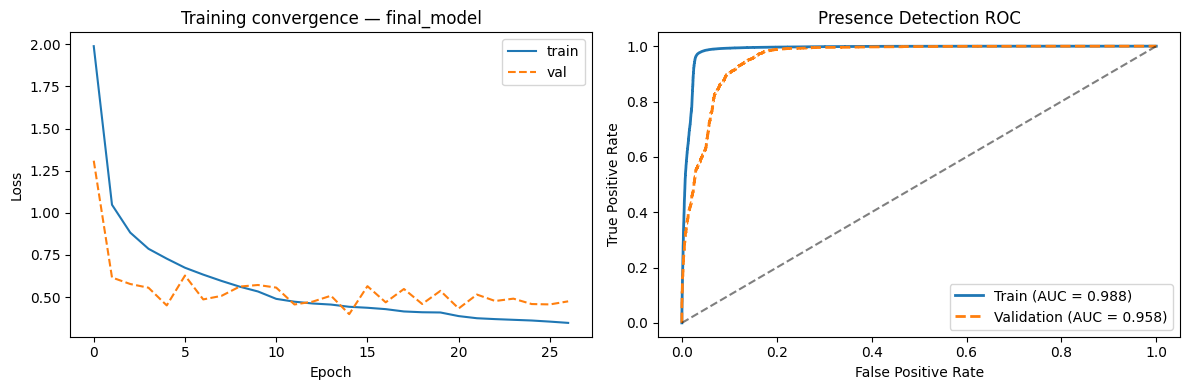

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist.history['loss'], label='train')
ax1.plot(hist.history['val_loss'], '--', label='val')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Training convergence — final_model'); ax1.legend()

# Validation ROC
fpr_val, tpr_val, _ = roc_curve(true_labels, pred_probs)
roc_auc_val = auc(fpr_val, tpr_val)

# Plot both curves
ax2.plot(fpr_train, tpr_train,
         label=f'Train (AUC = {roc_auc_train:.3f})',
         linewidth=2)

ax2.plot(fpr_val, tpr_val,
         '--',
         label=f'Validation (AUC = {roc_auc_val:.3f})',
         linewidth=2)

ax2.plot([0,1], [0,1], 'k--', alpha=0.5)

ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Presence Detection ROC')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / f"plots_{SUFFIX}.png"), dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
import shutil

# Save only the TFLite model into the submission directory
model_path = SUBMISSION_DIR / "model.tflite"

shutil.copy(tfl_path, model_path)

print(f"Saved TFLite model -> {model_path}")

Embedded calibration payload: 81.6 KB (base64)
Wrote /content/drive/MyDrive/EEAI_ds/submission/code.py  (88.6 KB)
Copied model.tflite -> /content/drive/MyDrive/EEAI_ds/submission/model.tflite


## 17 · Held-out test — run `code.py` + both official evaluators


In [ ]:
import subprocess

INPUT_TEST = Path("/content/drive/MyDrive/EEAI_ds/test/input_test.npy")
OUTPUT_GT  = Path("/content/drive/MyDrive/EEAI_ds/test/output_test.jsonl")
MY_OUTPUT  = Path("/content/drive/MyDrive/EEAI_ds/test/my_output.jsonl")
EVAL_DIR   = Path("/content/drive/MyDrive/EEAI_ds/evaluation")

# 1 - inference through the actual submission script
r = subprocess.run(["python", str(SUBMISSION_DIR / "code.py"),
                    "--input-path", str(INPUT_TEST),
                    "--output-path", str(MY_OUTPUT)],
                   capture_output=True, text=True)
print(r.stdout)
if r.stderr: print("STDERR:", r.stderr)
assert r.returncode == 0, "code.py failed — fix before submitting!"

# 2 - official performance evaluator
r = subprocess.run(["python", str(EVAL_DIR / "evaluate_performance.py"),
                    "--gt-path", str(OUTPUT_GT), "--pred-path", str(MY_OUTPUT)],
                   capture_output=True, text=True)
print(r.stdout)
if r.stderr: print("STDERR:", r.stderr)

# 3 - official constraint checker on the submitted model
r = subprocess.run(["python", str(EVAL_DIR / "evaluate_constraint.py"),
                    "--model-path", str(SUBMISSION_DIR / "model.tflite")],
                   capture_output=True, text=True)
print(r.stdout)
if r.stderr: print("STDERR:", r.stderr)


  frame 0/5000  (0s)
  frame 1000/5000  (5s)
  frame 2000/5000  (11s)
  frame 3000/5000  (16s)
  frame 4000/5000  (22s)
Inference pass done in 28s
Wrote 5000 frames -> /content/drive/MyDrive/EEAI_ds/test/my_output.jsonl

STDERR: /usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.

Output validation PASSED.
Loading files...
  Ground truth : 5000 frames   (output_test.jsonl)
  Predictions  : 5000 frames   (my_output.jsonl)
  Common frames                  : 5000

  DETECTION SCORE — F1
  Matching threshold  : 1.0 m
  Frames evaluated    : 5000
  TP / FP / FN        : 9984 / 16 / 16
  Precisi

## 18 · Cross Validation


In [ ]:
#Cross-validation configuration + per-window feature cache
from sklearn.model_selection import KFold

N_FOLDS   = 5           # 22 labelled windows -> folds of 5/5/4/4/4 acquisitions
CV_SEED   = 42          # fold assignment + augmentation reproducibility
CV_EPOCHS = EPOCHS      # same budget as the main run; EarlyStopping ends it sooner
CV_PATIENCE = 12

# The 22 labelled acquisitions (windows 22-23 are empty-room background only).
LABELED_WINDOWS = sorted(TRAIN_WINDOWS + VAL_WINDOWS)
assert set(LABELED_WINDOWS) == set(range(22)), LABELED_WINDOWS

# Human-readable scenario per window, straight from metadata.jsonl, so the
# per-fold report shows *what* each split is being validated on.
WIN_DESC = {}
for _cand in (DATA_DIR.parent / "metadata.jsonl",
              DATA_DIR / "metadata.jsonl",
               Path("/content/drive/MyDrive/EEAI_ds/metadata.jsonl"):

    try:
        if _cand.exists():
            for _l in open(_cand):
                _r = json.loads(_l)
                WIN_DESC[int(_r["window_id"].split("_")[-1])] = _r["description"]
            print(f"Loaded scenario descriptions from {_cand}")
            break
    except Exception as _e:
        pass
if not WIN_DESC:
    print("metadata.jsonl not found — folds will be reported without scenario labels")

def short_desc(w):
    d = WIN_DESC.get(w, "")
    return (d[:40] + "…") if len(d) > 41 else d

# Reclaim the RAM held by the single-split arrays: this diagnostic section runs
# after the submission is already built, so those big arrays are no longer
# needed. BG_COMPLEX / mu_norm / sd_norm are kept (still referenced elsewhere).
for _v in ("X_train_aug", "y_train_xy_aug", "y_train_mask_aug", "y_train_pack_aug",
           "X_train", "X_val", "y_train_xy", "y_train_mask",
           "X_train_raw", "X_val_raw"):
    if _v in globals():
        del globals()[_v]
gc.collect()

# Extract + cache features once per window (reuses build_split with a 1-window
# list). Cheap on repeat runs: build_split loads straight from the .npz cache.
print("\n--- Caching per-window features for cross-validation ---")
for _w in LABELED_WINDOWS:
    build_split([_w], f"cv_w{_w:03d}")
    gc.collect()

def load_windows(win_list):
    """Concatenate the cached feature arrays for a list of windows."""
    Xs, Ys, Ms = [], [], []
    for w in win_list:
        d = np.load(CACHE_DIR / f"feat_cv_w{w:03d}_{SUFFIX}.npz")
        Xs.append(d["X"]); Ys.append(d["y_xy"]); Ms.append(d["y_mask"])
    return (np.concatenate(Xs), np.concatenate(Ys), np.concatenate(Ms))

def best_threshold(y_pred, y_xy, y_mask, grid=np.linspace(0.05, 0.95, 19)):
    """Quiet presence-threshold sweep -> (best_th, best_metrics)."""
    best = (0.5, compute_f1(y_pred, y_xy, y_mask, 0.5))
    for t in grid:
        m = compute_f1(y_pred, y_xy, y_mask, float(t))
        if m["f1"] > best[1]["f1"]:
            best = (float(t), m)
    return best

# Deterministic window-level folds.
_kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_SEED)
FOLDS = [(np.array(LABELED_WINDOWS)[tr].tolist(),
          np.array(LABELED_WINDOWS)[va].tolist())
         for tr, va in _kf.split(LABELED_WINDOWS)]

print(f"\n{N_FOLDS}-fold split over {len(LABELED_WINDOWS)} acquisitions "
      f"(seed={CV_SEED}):")
for k, (tr_w, va_w) in enumerate(FOLDS):
    print(f"  fold {k}: val={va_w}  ({len(tr_w)} train / {len(va_w)} val windows)")


metadata.jsonl not found — folds will be reported without scenario labels

--- Caching per-window features for cross-validation ---
  window 000... +465 samples (2.8s)
Saved cv_w000: (465, 6, 3, 60, 6)
  window 001... +465 samples (2.0s)
Saved cv_w001: (465, 6, 3, 60, 6)
  window 002... +465 samples (2.0s)
Saved cv_w002: (465, 6, 3, 60, 6)
  window 003... +465 samples (2.0s)
Saved cv_w003: (465, 6, 3, 60, 6)
  window 004... +465 samples (5.4s)
Saved cv_w004: (465, 6, 3, 60, 6)
  window 005... +465 samples (2.0s)
Saved cv_w005: (465, 6, 3, 60, 6)
  window 006... +465 samples (2.1s)
Saved cv_w006: (465, 6, 3, 60, 6)
  window 007... +465 samples (2.0s)
Saved cv_w007: (465, 6, 3, 60, 6)
  window 008... +465 samples (4.5s)
Saved cv_w008: (465, 6, 3, 60, 6)
  window 009... +465 samples (3.2s)
Saved cv_w009: (465, 6, 3, 60, 6)
  window 010... +465 samples (2.0s)
Saved cv_w010: (465, 6, 3, 60, 6)
  window 011... +465 samples (2.5s)
Saved cv_w011: (465, 6, 3, 60, 6)
  window 012... +465 samples

In [ ]:
# Run the fold loop (train + evaluate a fresh model per split)
cv_records = []

for fold, (tr_w, va_w) in enumerate(FOLDS):
    print(f"\n{'='*70}")
    print(f"  FOLD {fold+1}/{N_FOLDS}  |  val windows {va_w}")
    print(f"{'='*70}")

    # --- assemble + normalise (train-only stats) + augment (train only) -------
    Xtr, ytr_xy, ytr_m = load_windows(tr_w)
    Xva, yva_xy, yva_m = load_windows(va_w)
    Xtr_n, Xva_n, _, _ = normalize(Xtr, Xva)
    del Xtr, Xva; gc.collect()

    Xtr_a, ytr_xy_a, ytr_m_a = augment(Xtr_n, ytr_xy, ytr_m, seed=CV_SEED + fold)
    del Xtr_n; gc.collect()
    ytr_pack = pack_labels(ytr_xy_a, ytr_m_a)
    yva_pack = pack_labels(yva_xy,   yva_m)
    print(f"  train samples: {Xtr_a.shape[0]:>6}  (x3 aug)   "
          f"val samples: {Xva_n.shape[0]:>6}")

    # --- fresh model, identical config to the single-split run ----------------
    keras.backend.clear_session()
    cv_model = build_model(Xtr_a.shape[1:])
    cv_model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
                     loss=perm_inv_loss)
    cbs = [
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.EarlyStopping(patience=CV_PATIENCE, restore_best_weights=True,
                                      monitor="val_loss"),
        keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5,
                                          monitor="val_loss", min_lr=1e-5),
    ]
    t0 = time.time()
    h = cv_model.fit(Xtr_a, ytr_pack, validation_data=(Xva_n, yva_pack),
                     epochs=CV_EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs,
                     verbose=0)
    dt = time.time() - t0

    # --- evaluate on this fold's held-out acquisitions ------------------------
    yq = cv_model.predict(Xva_n, batch_size=BATCH_SIZE, verbose=0)
    m0 = compute_f1(yq, yva_xy, yva_m, presence_th=0.5)
    bth, bm = best_threshold(yq, yva_xy, yva_m)

    rec = {
        "fold": fold,
        "val_windows": va_w,
        "val_scenarios": [short_desc(w) for w in va_w],
        "n_train_windows": len(tr_w), "n_val_windows": len(va_w),
        "n_train_samples": int(Xtr_a.shape[0]), "n_val_samples": int(Xva_n.shape[0]),
        "epochs_run": len(h.history["loss"]),
        "train_time_sec": round(dt, 1),
        "final_val_loss": float(h.history["val_loss"][-1]),
        # @0.5
        "f1": m0["f1"], "precision": m0["precision"], "recall": m0["recall"],
        "count_acc": m0["count_acc"], "count_mae": m0["count_mae"],
        "median_err": m0["median_err"], "p90_err": m0["p90_err"],
        # calibrated threshold
        "presence_th": bth, "f1_cal": bm["f1"],
        "precision_cal": bm["precision"], "recall_cal": bm["recall"],
        "count_acc_cal": bm["count_acc"],
    }
    cv_records.append(rec)

    print(f"  epochs={rec['epochs_run']:>3}  time={dt:5.1f}s  "
          f"|  F1@0.5={m0['f1']:.4f}  F1_cal={bm['f1']:.4f}@{bth:.2f}  "
          f"countAcc={m0['count_acc']:.4f}  medErr={m0['median_err']:.3f}m")

    del Xtr_a, Xva_n, ytr_pack, yva_pack, yq, cv_model, h; gc.collect()

print(f"\nAll {N_FOLDS} folds complete.")



  FOLD 1/5  |  val windows [0, 1, 8, 13, 15]
  train samples:  23715  (x3 aug)   val samples:   2325
  epochs= 63  time=268.3s  |  F1@0.5=0.8424  F1_cal=0.8428@0.70  countAcc=0.9247  medErr=0.385m

  FOLD 2/5  |  val windows [3, 4, 5, 11, 20]
  train samples:  23715  (x3 aug)   val samples:   2325
  epochs= 49  time=219.8s  |  F1@0.5=0.8574  F1_cal=0.8586@0.65  countAcc=0.9196  medErr=0.363m

  FOLD 3/5  |  val windows [12, 16, 17, 18]
  train samples:  25110  (x3 aug)   val samples:   1860
  epochs= 29  time=150.4s  |  F1@0.5=0.8714  F1_cal=0.8917@0.75  countAcc=0.7425  medErr=0.296m

  FOLD 4/5  |  val windows [2, 7, 9, 21]
  train samples:  25110  (x3 aug)   val samples:   1860
  epochs= 23  time=132.4s  |  F1@0.5=0.7691  F1_cal=0.7974@0.75  countAcc=0.7532  medErr=0.525m

  FOLD 5/5  |  val windows [6, 10, 14, 19]
  train samples:  25110  (x3 aug)   val samples:   1860
  epochs= 29  time=165.4s  |  F1@0.5=0.8243  F1_cal=0.8252@0.55  countAcc=0.7876  medErr=0.451m

All 5 folds comp

In [ ]:
# Aggregate: mean ± std across folds + save JSON
METRICS = [
    ("f1",        "F1@0.5",     "{:.4f}"),
    ("f1_cal",    "F1_cal",     "{:.4f}"),
    ("precision", "Precision",  "{:.4f}"),
    ("recall",    "Recall",     "{:.4f}"),
    ("count_acc", "CountAcc",   "{:.4f}"),
    ("count_mae", "CountMAE",   "{:.4f}"),
    ("median_err","MedErr(m)",  "{:.3f}"),
    ("p90_err",   "P90Err(m)",  "{:.3f}"),
]

def _stats(key):
    v = np.array([r[key] for r in cv_records], float)
    v = v[~np.isnan(v)]
    return (float(v.mean()), float(v.std())) if len(v) else (float("nan"), float("nan"))

cv_summary = {k: {"mean": _stats(k)[0], "std": _stats(k)[1]} for k, _, _ in METRICS}

# Per-fold table
hdr = f"{'fold':>4} {'val windows':<22} {'F1@0.5':>8} {'F1_cal':>8} {'th':>5} " \
      f"{'CountAcc':>9} {'MedErr':>7} {'P90':>7}"
print("="*len(hdr)); print("  CROSS-VALIDATION — per fold"); print("="*len(hdr))
print(hdr); print("-"*len(hdr))
for r in cv_records:
    print(f"{r['fold']:>4} {str(r['val_windows']):<22} "
          f"{r['f1']:>8.4f} {r['f1_cal']:>8.4f} {r['presence_th']:>5.2f} "
          f"{r['count_acc']:>9.4f} {r['median_err']:>7.3f} {r['p90_err']:>7.3f}")

# Mean ± std
print("\n" + "="*len(hdr)); print("  CROSS-VALIDATION — mean ± std across folds")
print("="*len(hdr))
for key, label, fmt in METRICS:
    mu, sd = _stats(key)
    print(f"  {label:<11} = {fmt.format(mu)}  ±  {fmt.format(sd)}")

# Scenario breakdown so it's clear what each split validated on
print("\n  Scenario mix per fold (from metadata.jsonl):")
for r in cv_records:
    labels = "; ".join(f"w{w}:{s}" for w, s in zip(r["val_windows"], r["val_scenarios"]))
    print(f"   fold {r['fold']}: {labels}")

# Persist everything next to the other result files
cv_out = {
    "config_name": "final_model", "suffix": SUFFIX,
    "n_folds": N_FOLDS, "cv_seed": CV_SEED,
    "split_level": "window (leakage-safe)",
    "labeled_windows": LABELED_WINDOWS,
    "per_fold": cv_records,
    "summary_mean_std": cv_summary,
}
cv_path = RESULTS_DIR / f"cv_results_{SUFFIX}.json"
cv_path.write_text(json.dumps(cv_out, indent=2))
print(f"\nSaved cross-validation results -> {cv_path}")
print(f"Headline: F1@0.5 = {cv_summary['f1']['mean']:.4f} ± {cv_summary['f1']['std']:.4f}"
      f"   |   F1_cal = {cv_summary['f1_cal']['mean']:.4f} ± {cv_summary['f1_cal']['std']:.4f}")


  CROSS-VALIDATION — per fold
fold val windows              F1@0.5   F1_cal    th  CountAcc  MedErr     P90
-----------------------------------------------------------------------------
   0 [0, 1, 8, 13, 15]        0.8424   0.8428  0.70    0.9247   0.385   0.813
   1 [3, 4, 5, 11, 20]        0.8574   0.8586  0.65    0.9196   0.363   0.759
   2 [12, 16, 17, 18]         0.8714   0.8917  0.75    0.7425   0.296   0.678
   3 [2, 7, 9, 21]            0.7691   0.7974  0.75    0.7532   0.525   0.904
   4 [6, 10, 14, 19]          0.8243   0.8252  0.55    0.7876   0.451   0.831

  CROSS-VALIDATION — mean ± std across folds
  F1@0.5      = 0.8329  ±  0.0356
  F1_cal      = 0.8431  ±  0.0317
  Precision   = 0.8141  ±  0.0407
  Recall      = 0.8544  ±  0.0498
  CountAcc    = 0.8255  ±  0.0803
  CountMAE    = 0.1745  ±  0.0803
  MedErr(m)   = 0.404  ±  0.078
  P90Err(m)   = 0.797  ±  0.075

  Scenario mix per fold (from metadata.jsonl):
   fold 0: w0:; w1:; w8:; w13:; w15:
   fold 1: w3:; w4:; w5:;

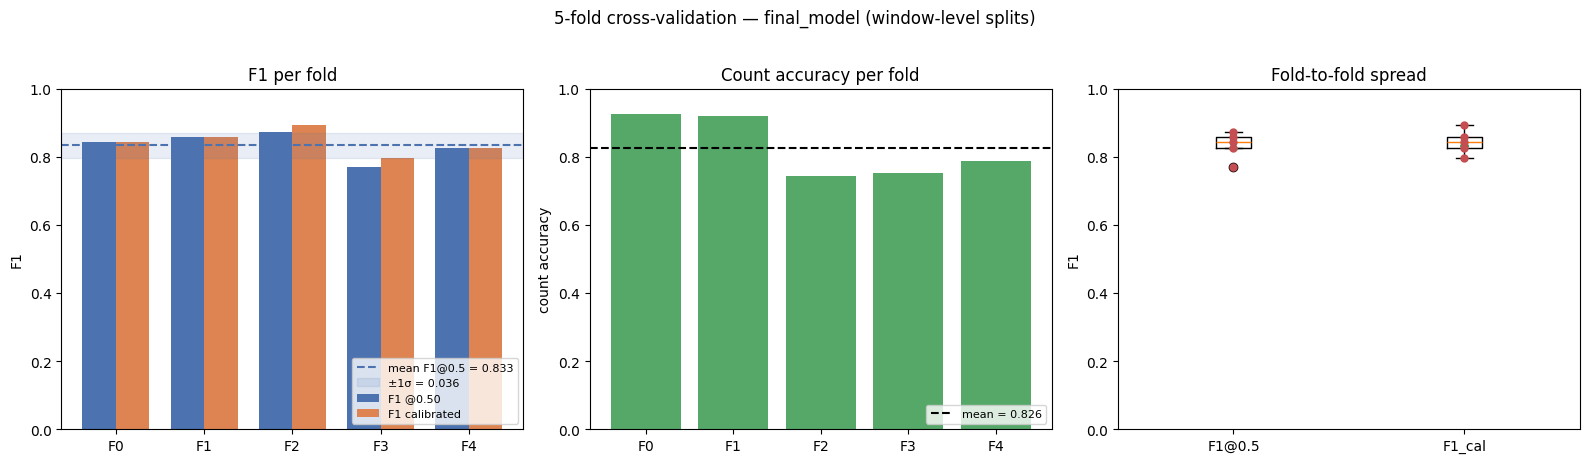

F1@0.5 across folds: mean 0.8329  std 0.0356  min 0.7691  max 0.8714


In [ ]:
# 19.4 · Visualise the spread across splits
folds   = [r["fold"] for r in cv_records]
f1s     = [r["f1"] for r in cv_records]
f1cals  = [r["f1_cal"] for r in cv_records]
caccs   = [r["count_acc"] for r in cv_records]
mederrs = [r["median_err"] for r in cv_records]

f1_mu, f1_sd       = cv_summary["f1"]["mean"], cv_summary["f1"]["std"]
f1cal_mu           = cv_summary["f1_cal"]["mean"]
cacc_mu            = cv_summary["count_acc"]["mean"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(folds)); w = 0.38

# (1) F1 per fold: raw @0.5 vs calibrated, with the CV mean band
ax = axes[0]
ax.bar(x - w/2, f1s,    w, label="F1 @0.50",  color="#4C72B0")
ax.bar(x + w/2, f1cals, w, label="F1 calibrated", color="#DD8452")
ax.axhline(f1_mu, ls="--", c="#4C72B0", lw=1.5,
           label=f"mean F1@0.5 = {f1_mu:.3f}")
ax.axhspan(f1_mu - f1_sd, f1_mu + f1_sd, color="#4C72B0", alpha=0.12,
           label=f"±1σ = {f1_sd:.3f}")
ax.set_xticks(x); ax.set_xticklabels([f"F{i}" for i in folds])
ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("F1 per fold")
ax.legend(fontsize=8, loc="lower right")

# (2) Count accuracy per fold
ax = axes[1]
ax.bar(x, caccs, color="#55A868")
ax.axhline(cacc_mu, ls="--", c="k", lw=1.5, label=f"mean = {cacc_mu:.3f}")
ax.set_xticks(x); ax.set_xticklabels([f"F{i}" for i in folds])
ax.set_ylim(0, 1); ax.set_ylabel("count accuracy")
ax.set_title("Count accuracy per fold"); ax.legend(fontsize=8, loc="lower right")

# (3) Distribution of the fold F1 scores (how tight is the spread?)
ax = axes[2]
ax.boxplot([f1s, f1cals], showmeans=True)
ax.set_xticks([1, 2]); ax.set_xticklabels(["F1@0.5", "F1_cal"])
for i, vals in enumerate([f1s, f1cals], start=1):
    ax.scatter(np.full(len(vals), i), vals, c="#C44E52", zorder=3, s=25)
ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("Fold-to-fold spread")

plt.suptitle(f"{N_FOLDS}-fold cross-validation — final_model "
             f"(window-level splits)", y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / f"cv_plots_{SUFFIX}.png"), dpi=150,
            bbox_inches="tight")
plt.show()

print(f"F1@0.5 across folds: mean {f1_mu:.4f}  std {f1_sd:.4f}  "
      f"min {min(f1s):.4f}  max {max(f1s):.4f}")
